# Quimiometría aplicada a espectroscopía NIR: predicción de grasa con PLS

**Portfolio técnico · Química + Data Science**

## Objetivo
Estimar el porcentaje de grasa de muestras a partir de espectros NIR. El proyecto recorre un flujo reproducible: control inicial de datos, exploración espectral, PCA, calibración PLS, comparación con modelos alternativos y evaluación final en muestras reservadas.

**Dataset:** Tecator, 215 muestras originales, 100 canales de absorbancia entre 850 y 1050 nm. Los porcentajes de grasa, agua y proteína se obtuvieron mediante química analítica. Fuente y nota de permiso: [documentación del dataset](https://modeldata.tidymodels.org/reference/meats.html).

> Interpretación importante: este conjunto de datos es un benchmark de carne, no un conjunto de datos de aceites o medicamentos. Las técnicas son transferibles, pero los resultados no validan directamente un método industrial o farmacéutico.

## 1. Preparar el entorno y ejecutar el análisis

Instala las dependencias con `pip install -r requirements.txt`. La primera ejecución descarga el CSV público. El análisis elimina duplicados exactos **antes** de separar entrenamiento y prueba para reducir la fuga de datos.

El flujo completo está implementado en `src/analisis_nir.py` para que también pueda ejecutarse desde terminal y sea más fácil de mantener.

> Nota: de las 215 muestras originales, 22 eran duplicados exactos y se eliminaron, por lo que el análisis usa **193 muestras únicas** (154 de entrenamiento y 39 de prueba).

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analisis_nir import main

main()

Descargando dataset Tecator desde Rdatasets...
Ajustando PLS_espectro_original...
Ajustando PLS_primera_derivada...
Ajustando Ridge...
Ajustando RandomForest...

RESUMEN DE EJECUCIÓN — TECATOR NIR
Filas válidas antes de deduplicar: 215
Filas con valores ausentes eliminadas: 0
Duplicados exactos eliminados: 22
Muestras únicas analizadas: 193
Entrenamiento: 154 | Prueba: 39
Mejor RMSE de prueba: PLS_espectro_original
RMSE test: 1.822 puntos porcentuales
MAE test: 1.452 puntos porcentuales
R² test: 0.980

Interpretar estos resultados en el contexto del tamaño de muestra y de la partición utilizada.
No equivalen a validación externa industrial ni sustituyen un método de referencia validado.

Resultados guardados en: C:\Users\josem\Desktop\Portfolio\Proyecto quimica\proyecto_quimiometria_nir\results


## 2. Métricas de los modelos

La tabla se genera después de ejecutar la validación cruzada en entrenamiento y la evaluación final sobre el conjunto de prueba. El RMSE y el MAE están expresados en **puntos porcentuales de grasa**. R² resume la proporción de variabilidad explicada en esta partición; no debe interpretarse de forma aislada.

In [2]:
metrics_path = ROOT / "results" / "metricas_modelos.csv"
metrics = pd.read_csv(metrics_path)
display(metrics.round(3))

,modelo,rmse_test,mae_test,r2_test,rmse_cv_entrenamiento,mejores_parametros
0,PLS_espectro_original,1.822,1.452,0.980,2.734,{'pls__n_components': 14}
1,Ridge,2.364,1.815,0.967,3.040,{'ridge__alpha': 0.01}
2,PLS_primera_derivada,2.424,2.012,0.965,2.941,{'pls__n_components': 8}
3,RandomForest,7.090,5.317,0.699,8.604,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es..."


## 3. Inspección visual

- **Espectros:** muestran la forma y variabilidad de las señales de absorbancia.
- **Distribución de grasa:** ayuda a entender el rango cubierto por las muestras.
- **PCA:** proyección exploratoria de los espectros; el color indica el valor de referencia de grasa. La proximidad en PCA no demuestra por sí sola causalidad ni calidad predictiva.
- **Observado vs. predicho y residuos:** permiten identificar sesgo, errores grandes y patrones que sugieran limitaciones del modelo.

01_espectros_nir.png


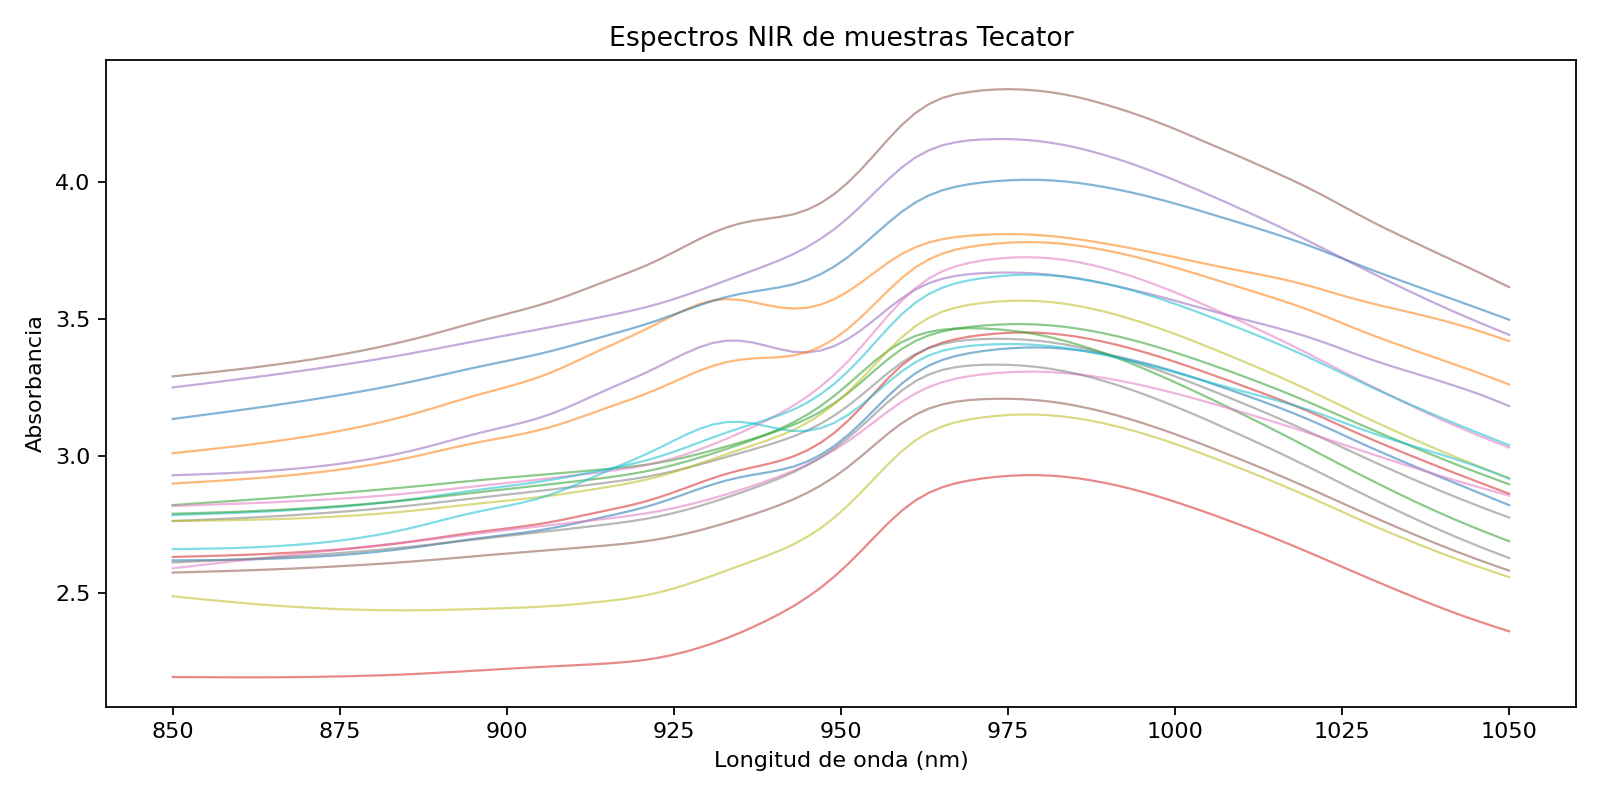

02_distribucion_grasa.png


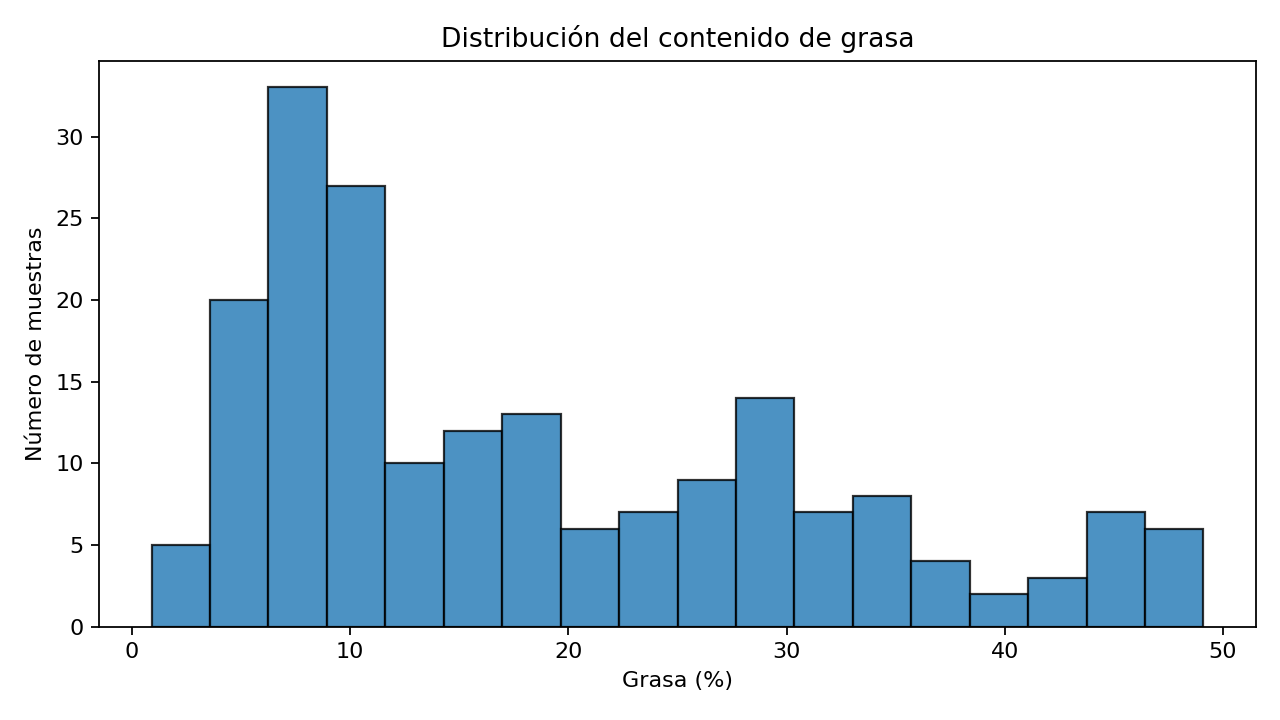

03_pca_espectros.png


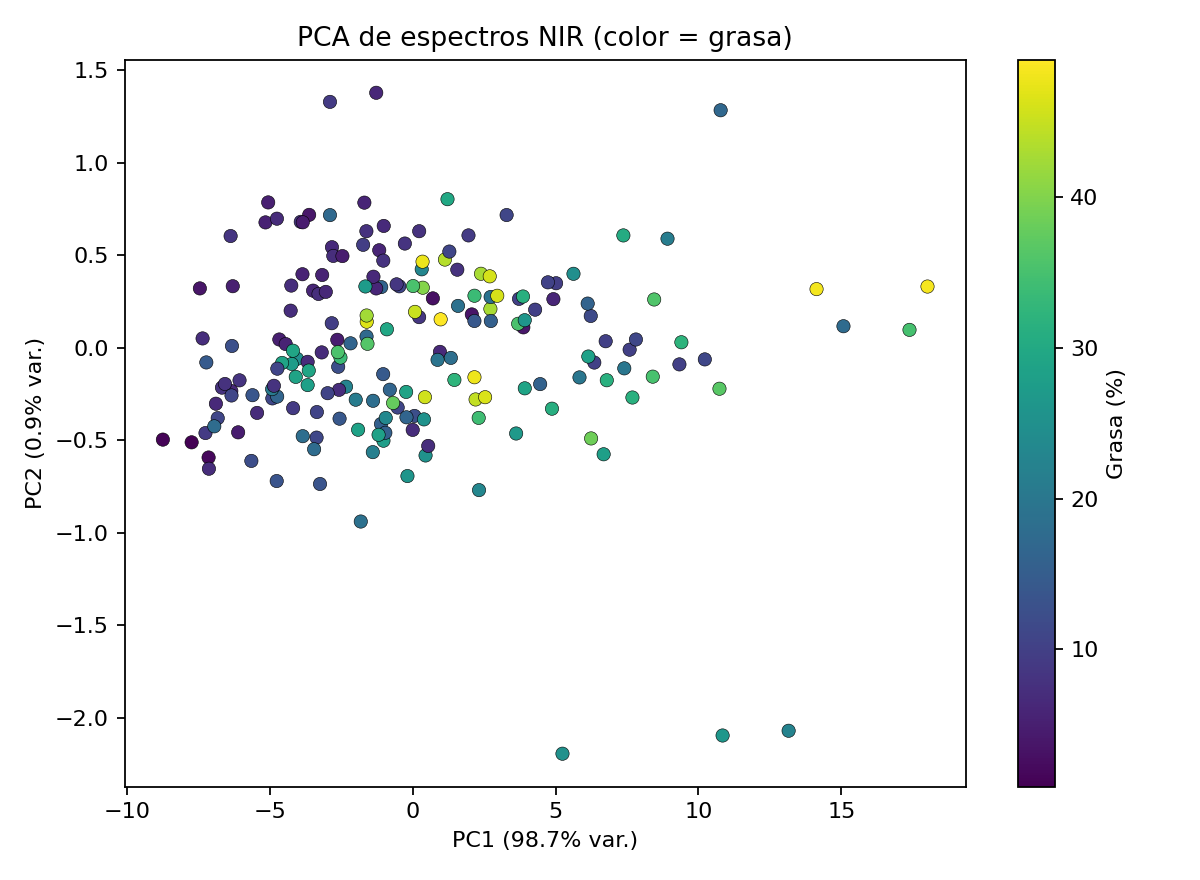

04_observado_vs_predicho.png


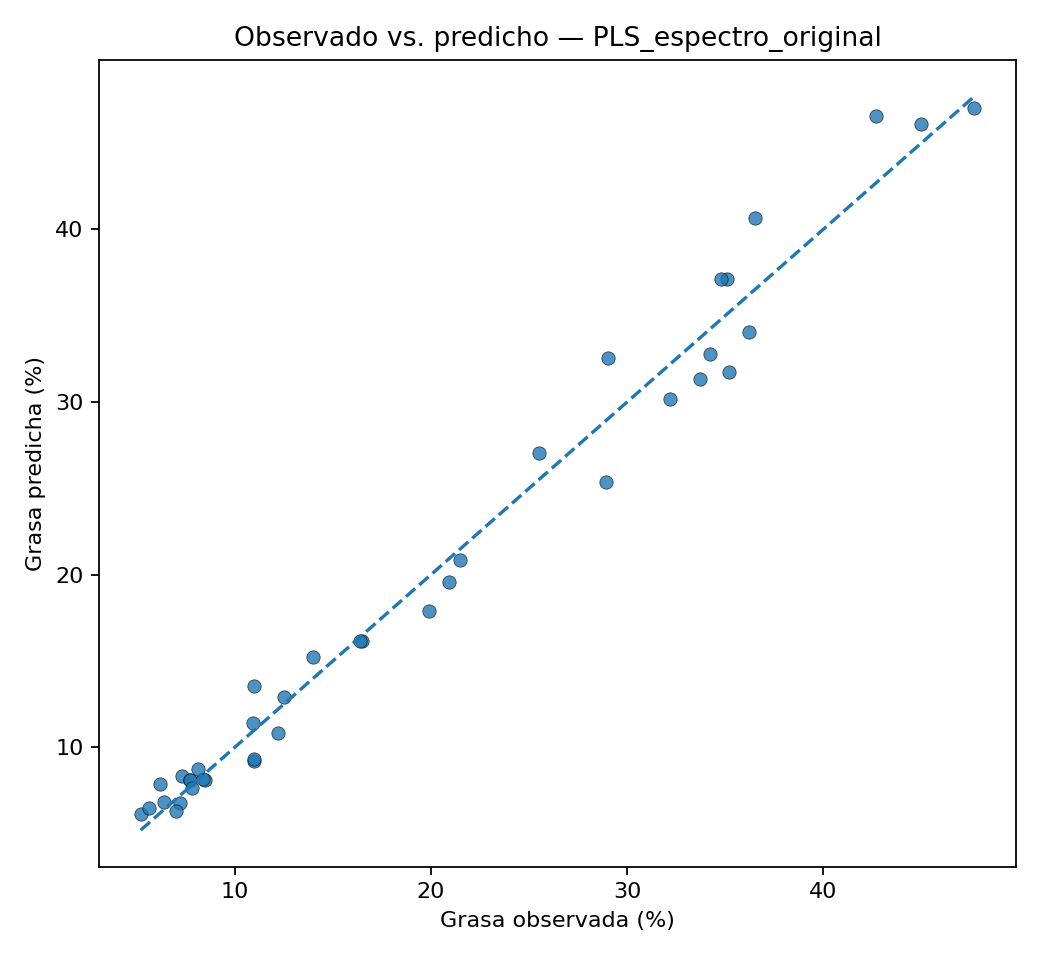

05_residuos.png


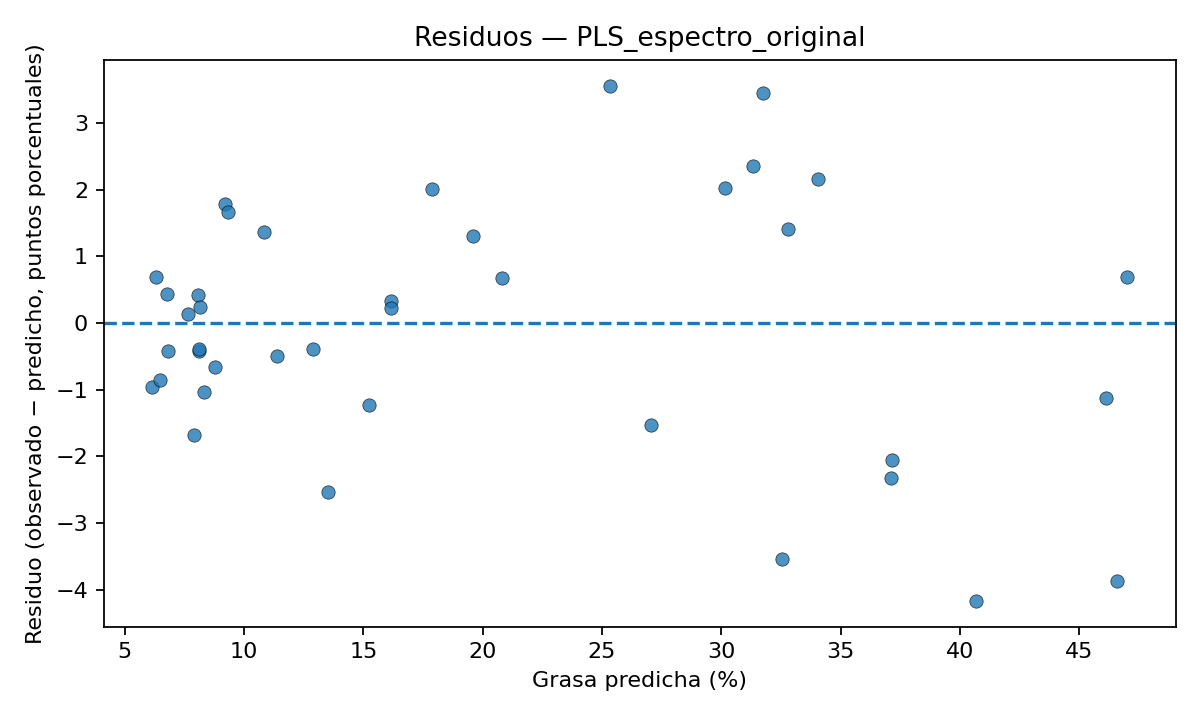

In [3]:
figure_dir = ROOT / "results" / "figures"
for filename in [
    "01_espectros_nir.png",
    "02_distribucion_grasa.png",
    "03_pca_espectros.png",
    "04_observado_vs_predicho.png",
    "05_residuos.png",
]:
    print(filename)
    display(Image(filename=str(figure_dir / filename)))

## 4. Lecturas de gráficas y Conclusiones

### Lectura de las gráficas

1. **Espectros NIR.** Las curvas comparten una forma común, con un hombro cerca de 930 nm y un máximo en torno a 970–980 nm. La mayor diferencia entre muestras es un desplazamiento vertical de la línea base (de ~2.2 a ~4.3 de absorbancia). Este efecto aditivo (dispersión de luz, textura) justifica probar una derivada, aunque en este caso no mejoró el resultado.

2. **Distribución de grasa.** Es asimétrica: la mayoría de muestras está entre 5 y 20 %, con un máximo en 7–10 %, y hay una cola larga hasta ~49 %, con pocas muestras por encima de 38 %. El modelo estará mejor calibrado en el rango bajo y medio, y será menos fiable en los extremos altos.

3. **PCA.** PC1 explica el 98.7 % de la varianza y PC2 solo el 0.9 %, lo que indica que el espectro está dominado por un único patrón, probablemente el efecto de línea base. Hay un gradiente de grasa a lo largo de PC1 (baja a la izquierda, alta a la derecha) con bastante solapamiento, por lo que PC1 por sí sola no basta y PLS aprovecha información más sutil. Unos pocos puntos aislados podrían ser espectros atípicos y conviene revisarlos.

4. **Observado vs. predicho.** Los puntos siguen bien la diagonal en todo el rango (5–48 %), con R² = 0.98 y MAE = 1.45 puntos porcentuales, sin curvatura sistemática. Los errores más visibles están en el rango alto (por ejemplo, una muestra de ~29 % predicha como ~25 %).

5. **Residuos.** Se reparten alrededor de cero, sin sesgo claro. Hay heterocedasticidad leve: entre 5 y 20 % casi todos quedan dentro de ±2 puntos, y por encima de 25 % llegan a ±3.5–4.2. Es coherente con la menor densidad de muestras en grasa alta.

### Conclusiones generales

Valores obtenidos con `random_state=42`, 154 muestras de entrenamiento y 39 de prueba.

1. **¿Qué modelo presenta el menor RMSE en el conjunto de prueba?**

   PLS sobre el espectro original (RMSE = 1.82 puntos porcentuales de grasa).

2. **¿La primera derivada Savitzky–Golay mejora la calibración frente al espectro original?**

   No, el RMSE en prueba empeora (2.42 frente a 1.82). En una comprobación con 40 particiones aleatorias, el PLS sobre espectro original superó a la derivada en la mayoría (31 de 40), aunque con una diferencia media pequeña (~0.15 puntos porcentuales). La derivada no ofrece una ventaja clara de parsimonia: con CV repetida su número óptimo de variables latentes es ~12, no 8. La ventana (11) y el orden del polinomio (2) se mantuvieron fijos y no se optimizaron.

3. **¿Las diferencias entre RMSE de validación cruzada y RMSE de prueba sugieren inestabilidad?**

   El RMSE de prueba (1.82) es menor que el de validación cruzada (2.73). Con 40 particiones aleatorias el RMSE de prueba medio fue de ~2.6 (rango 1.9–4.5), por lo que la partición con semilla 42 resultó favorable. El RMSE de validación cruzada (~2.7) es la estimación más realista del error esperado.

4. **¿Los residuos muestran sesgo o errores mayores en algún rango de grasa?**

   No hay sesgo evidente, pero la dispersión es mayor por encima de ~25 % de grasa.

5. **¿El tamaño muestral y la ausencia de validación externa limitan las conclusiones?**

   Sí, con 39 muestras de prueba, una única partición y sin validación externa, los resultados son orientativos. El PLS elegido usa 14 de un máximo de 15 componentes y el mejor `alpha` de Ridge (0.01) coincide con el límite inferior de su rejilla, por lo que convendría ampliar ambas rejillas y el ranking entre modelos debe considerarse provisional. Random Forest rinde peor (R² = 0.70), posiblemente porque trabaja peor con variables espectrales muy colineales y pocas muestras.

### Conclusión profesional

En la partición de referencia, PLS sobre el espectro original obtuvo el menor RMSE en prueba (1.82 puntos porcentuales de grasa), pero el error esperado es mayor: ~2.7 según validación cruzada y ~2.6 de media en 40 particiones aleatorias. La ventaja sobre Ridge y PLS con primera derivada es pequeña y depende de la partición y de la rejilla de hiperparámetros, por lo que no es concluyente. Antes de cualquier aplicación real habría que validar con muestras externas representativas y compararlo con un método de referencia. Este ejercicio demuestra la capacidad de aplicar un flujo quimiométrico reproducible, no una validación regulada.

## 5. Reproducibilidad y trazabilidad

- Semilla aleatoria fijada (`42`).
- Duplicados exactos eliminados antes de la partición.
- Ajuste de hiperparámetros mediante validación cruzada solo en entrenamiento.
- Conjunto de prueba reservado para la evaluación final.
- Métricas, predicciones y figuras guardadas en `results/`.
- Código principal reproducible también desde `python src/analisis_nir.py`.

**Fuentes:**
- [Descripción y nota de permiso Tecator / modeldata](https://modeldata.tidymodels.org/reference/meats.html)
- [CSV del dataset](https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/modeldata/meats.csv)